# 01 — Load and render a ShapeSplats chair

Goal: get one `chair_XXXX/point_cloud.ply` onto the screen so we can confirm the data is
what we think it is, before writing any model code.

We render **without** `gsplat` or any CUDA extension. `splatlib.py` contains a
small pure-numpy EWA splatting rasteriser (~100 lines). It is slower than a real
rasteriser but needs no compilation, runs anywhere, and — more importantly — the
projection maths is visible and editable. That maths is the same maths the
GaussianCube paper assumes you already know, so it is worth reading once.

**Contents**
1. Locate the files (directory-per-object layout)
2. Inspect the raw PLY — what is actually stored
3. Parse and apply activations
4. Sanity-check one object numerically
5. Interactive point cloud (fast look)
6. Real splat rendering
7. Which axis is up?
8. A grid of many chairs

## 1. Locate the files

Set `DATA_ROOT` to wherever the extracted dataset lives. Everything else follows.

**Layout note.** ShapeSplats/ModelNet_Splats does *not* store one `chair_0001.ply`
per object. Each object is its own **directory**, and the file inside is always
called `point_cloud.ply`:

```
DATA_ROOT/
  chair_0001/point_cloud.ply
  chair_0002/point_cloud.ply
  night_stand_0042/point_cloud.ply
```

So the object identity lives in the *directory* name, not the filename. Any code
that keys off `path.stem` sees `"point_cloud"` for every object and silently
collapses the whole dataset into one name. We parse `{category}_{index}` off the
parent directory instead.

In [1]:
import os, sys, time, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import splatlib as sl

# Adjust if your mount point differs. /data is usually a bind mount of /lustre/data/<user>.
CANDIDATES = [
    "/lustre/data/mls04/ModelNet_Splats/extracted/train",
    "/data/ModelNet_Splats/extracted/train",
    os.environ.get("DATASET_DIR", "") + "/extracted/train",
]
DATA_ROOT = next((Path(c) for c in CANDIDATES if c and Path(c).is_dir()), None)
assert DATA_ROOT is not None, f"none of these exist:\n  " + "\n  ".join(CANDIDATES)

OUT = Path.home() / "psiml" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

print("data root :", DATA_ROOT)
print("outputs   :", OUT)
print("numpy     :", np.__version__)

data root : /data/ModelNet_Splats/extracted/train
outputs   : /home/mls04/psiml/outputs
numpy     : 2.4.6


In [3]:
import re
from collections import Counter

# Matches "chair_0001", and also multi-word categories like
# "night_stand_0042" / "tv_stand_0003" -- we split on the LAST underscore only.
OBJ_RE = re.compile(r"^(?P<cat>.+)_(?P<idx>\d+)$")


def parse_object_dir(d: Path):
    """('chair_0001') -> ('chair', 1). Returns None if the name doesn't match."""
    m = OBJ_RE.match(d.name)
    return (m.group("cat"), int(m.group("idx"))) if m else None


def find_objects(root, category=None, split=None):
    """
    Locate objects under `root`, handling both dataset layouts:
        root/[split/]{category}_{index}/point_cloud.ply   <- ShapeSplats
        root/[split/]{category}_{index}.ply               <- flat fallback
    Returns a list of Paths to the .ply files, sorted by (category, index).
    """
    root = Path(root)
    found = []

    # layout A: one directory per object
    for ply in root.rglob("point_cloud.ply"):
        parsed = parse_object_dir(ply.parent)
        if parsed is None:
            continue
        cat, idx = parsed
        parts = ply.parent.relative_to(root).parts
        spl = parts[0] if len(parts) > 1 else None
        found.append((ply, cat, idx, spl))

    # layout B: flat *.ply named after the object (only if A found nothing)
    if not found:
        for ply in root.rglob("*.ply"):
            if ply.name == "point_cloud.ply":
                continue
            m = OBJ_RE.match(ply.stem)
            if not m:
                continue
            cat, idx = m.group("cat"), int(m.group("idx"))
            parts = ply.parent.relative_to(root).parts
            spl = parts[0] if parts else None
            found.append((ply, cat, idx, spl))

    found = [r for r in found
             if (category is None or r[1] == category)
             and (split is None or r[3] == split)]
    found.sort(key=lambda r: (r[1], r[2]))
    return [r[0] for r in found], found


def object_id(path: Path) -> str:
    """Stable name for an object: 'chair_0001'. Never use path.stem -- it is
    'point_cloud' for every object in this dataset."""
    p = Path(path)
    return p.parent.name if p.name == "point_cloud.ply" else p.stem


def load(path):
    """load_ply + attach a usable .name (splatlib derives it from the filename,
    which is 'point_cloud' here)."""
    s = sl.load_ply(path)
    try:
        s.name = object_id(path)
    except Exception:
        pass  # frozen dataclass / namedtuple -- use object_id(path) directly
    return s


# ---------------------------------------------------------------- inventory
t0 = time.time()
_, all_objs = find_objects(DATA_ROOT)
print(f"{len(all_objs)} objects found in {time.time()-t0:.1f}s")

by_cat = Counter(c for _, c, _, _ in all_objs)
by_split = Counter(s for _, _, _, s in all_objs)
print("splits    :", dict(by_split) if any(by_split) else "(none -- DATA_ROOT is already a split)")
print(f"categories: {len(by_cat)}")
for cat, n in by_cat.most_common():
    print(f"    {cat:<16} {n}")

9842 objects found in 10.5s
splits    : (none -- DATA_ROOT is already a split)
categories: 40
    chair            889
    sofa             680
    airplane         626
    bookshelf        572
    bed              515
    vase             475
    monitor          465
    table            392
    toilet           344
    bottle           335
    mantel           284
    tv_stand         267
    plant            240
    piano            231
    desk             200
    dresser          200
    night_stand      200
    car              197
    bench            173
    glass_box        171
    cone             167
    tent             163
    guitar           155
    flower_pot       149
    laptop           149
    keyboard         145
    curtain          138
    sink             128
    stairs           124
    lamp             123
    range_hood       115
    door             109
    bathtub          106
    radio            104
    xbox             103
    stool            90
    per

In [6]:
CATEGORY = "chair"

files, meta = find_objects(DATA_ROOT, category=CATEGORY)
assert files, (f"no '{CATEGORY}' objects under {DATA_ROOT}. "
               f"Available: {sorted({c for _, c, _, _ in all_objs})}")

print(f"{len(files)} '{CATEGORY}' objects")
print("first    :", object_id(files[0]), " last:", object_id(files[-1]))
print("example  :", files[0].relative_to(DATA_ROOT))
print("size     :", f"{files[0].stat().st_size / 1e6:.1f} MB")

# Object ids are what we key everything on from here: cached tensors, the
# train/test split file, figure filenames. Filenames are all identical.
OBJ_IDS = [object_id(p) for p in files]
print("ids      :", OBJ_IDS[:3], "...", OBJ_IDS[-1])

889 'chair' objects
first    : chair_0001  last: chair_0889
example  : chair_0001/point_cloud.ply
size     : 7.7 MB
ids      : ['chair_0001', 'chair_0002', 'chair_0003'] ... chair_0889


## 2. Inspect the raw PLY

Never trust a loader you did not check against the file. Print the actual
property names first — the number of `f_rest_*` fields tells you the spherical
harmonics degree, and whether the file even stores view-dependent colour.

A standard 3DGS PLY at SH degree 3 has 62 float properties per vertex:

| group | count | meaning |
|---|---|---|
| `x,y,z` | 3 | Gaussian centre |
| `nx,ny,nz` | 3 | normals — legacy, almost always zero |
| `f_dc_0..2` | 3 | SH degree-0 coefficient = base colour |
| `f_rest_0..44` | 45 | SH degrees 1–3, view-dependent colour |
| `opacity` | 1 | **logit** of opacity |
| `scale_0..2` | 3 | **log** of the three ellipsoid axis lengths |
| `rot_0..3` | 4 | quaternion `(w,x,y,z)`, unnormalised |

In [7]:
ply = sl.describe_ply(files[0])

file    : point_cloud.ply
format  : format binary_little_endian 1.0
element : vertex  count=30848  properties=62
    x            x1    e.g. ['x']
    y            x1    e.g. ['y']
    z            x1    e.g. ['z']
    nx           x1    e.g. ['nx']
    ny           x1    e.g. ['ny']
    nz           x1    e.g. ['nz']
    f_dc_*       x3    e.g. ['f_dc_0', 'f_dc_1', 'f_dc_2']
    f_rest_*     x45   e.g. ['f_rest_0', 'f_rest_1', 'f_rest_2']
    opacity      x1    e.g. ['opacity']
    scale_*      x3    e.g. ['scale_0', 'scale_1', 'scale_2']
    rot_*        x4    e.g. ['rot_0', 'rot_1', 'rot_2']

  first 6 rows, first 8 columns:
             x           y           z          nx          ny          nz      f_dc_0      f_dc_1
       -0.2787     -0.0019     -0.0406      0.0000      0.0000      0.0000     -0.5507     -0.5499
       -0.0845     -0.0247     -0.0423      0.0000      0.0000      0.0000     -0.9125     -0.9088
       -0.1383     -0.0326     -0.0391      0.0000      0.0000     

Note the raw magnitudes above: `opacity` and `scale_*` are far outside the
ranges you would expect for a probability and a length. That is because they are
stored pre-activation. **Reading them directly is the most common way to get
plausible-looking but wrong statistics.**

## 3. Parse and apply activations

```
opacity  =  sigmoid(raw)          -> (0, 1)
scale    =  exp(raw)              -> positive lengths
quat     =  raw / ||raw||         -> unit quaternion
rgb      =  0.5 + C0 * f_dc       -> [0,1],  C0 = 0.5/sqrt(pi)
```

Two details that quietly corrupt loaders:

- `f_rest_10` sorts before `f_rest_2` lexically. Sorting SH coefficients as
  strings scrambles them. `splatlib` sorts numerically.
- The quaternion convention is `w` first, not last. Getting this wrong gives
  rotated-but-still-plausible ellipsoids, which is very hard to spot by eye.

In [8]:
sp = load(files[0])
OBJ_ID = object_id(files[0])

print(f"{OBJ_ID}: {len(sp):,} gaussians, SH degree {sp.sh_degree} "
      f"({sp.f_rest.shape[1]} rest coefficients)")
print()
for k, v in sp.summary().items():
    print(f"  {k:<14} {v}")

chair_0001: 30,848 gaussians, SH degree 3 (45 rest coefficients)

  name           chair_0001
  n_gaussians    30848
  sh_degree      3
  n_sh_rest      45
  bbox_min       [-0.3887999951839447, -0.2786000072956085, -0.5388000011444092]
  bbox_max       [0.24580000340938568, 0.2793999910354614, 0.46399998664855957]
  extent         [0.6345999836921692, 0.5580000281333923, 1.0029000043869019]
  centroid       [-0.013899999670684338, 0.0034000000450760126, -0.00989999994635582]
  scale_median   [0.0026199999265372753, 0.006060000043362379, 0.004600000102072954]
  opacity_mean   0.3463999927043915
  rgb_mean       [0.4050000011920929, 0.4050000011920929, 0.4050000011920929]


In [9]:
sp.raw_scale

array([[ -4.0127697,  -3.3630834,  -4.9149785],
       [ -4.402209 ,  -4.22811  ,  -4.8380766],
       [ -3.7943022,  -4.1580477,  -4.8142395],
       ...,
       [-11.565932 ,  -5.9266477,  -3.3454206],
       [ -9.411009 ,  -5.8210196,  -4.33452  ],
       [ -6.656232 , -10.666961 ,  -2.9909198]],
      shape=(30848, 3), dtype=float32)

In [10]:
# Raw vs activated, side by side -- worth internalising.
rows = [
    ("scale_0 (log)",  sp.raw_scale[:, 0],  "scale x",      sp.scale[:, 0]),
    ("opacity (logit)", sp.raw_opacity,     "opacity",      sp.opacity),
    ("f_dc_0",          sp.f_dc[:, 0],      "R",            sp.rgb[:, 0]),
]
print(f"{'raw field':<18}{'min':>9}{'med':>9}{'max':>9}   "
      f"{'activated':<12}{'min':>8}{'med':>8}{'max':>8}")
for rn, r, an, a in rows:
    print(f"{rn:<18}{r.min():>9.3f}{np.median(r):>9.3f}{r.max():>9.3f}   "
          f"{an:<12}{a.min():>8.3f}{np.median(a):>8.3f}{a.max():>8.3f}")

raw field               min      med      max   activated        min     med     max
scale_0 (log)       -14.876   -5.943   -2.674   scale x        0.000   0.003   0.069
opacity (logit)      -5.099   -0.970    8.446   opacity        0.006   0.275   1.000
f_dc_0               -1.844   -0.542    2.968   R              0.000   0.347   1.000


In [11]:
raw = sp.raw_scale
print("log-scale percentiles:",
      np.percentile(raw, [0, 0.1, 1, 50, 99, 99.9, 100]).round(2))
print("frac with any axis < exp(-12):", (raw < -12).any(1).mean())

log-scale percentiles: [-14.88 -13.36 -11.02  -5.52  -3.2   -2.78  -1.9 ]
frac with any axis < exp(-12): 0.011929460580912862


## 4. Sanity checks

If any of these fail, stop and fix the loader before looking at pictures.
A wrong loader produces images that look *almost* right.

In [12]:
s = sp.scale[:200].astype(np.float64)
q = sp.quat[:200].astype(np.float64)

cov = sl.covariance_3d(s, q)
cov = 0.5 * (cov + cov.transpose(0, 2, 1))        # kill asymmetry from roundoff
ev  = np.linalg.eigvalsh(cov)

rec = np.sort(np.sqrt(np.clip(ev, 0, None)), 1)
tgt = np.sort(s, 1)
err = np.abs(rec - tgt)
bad = np.unravel_index(np.argmax(err / np.maximum(tgt, 1e-30)), err.shape)

print(f"worst gaussian {bad[0]}, axis {bad[1]}")
print(f"  true scale   {tgt[bad]:.6e}")
print(f"  recovered    {rec[bad]:.6e}")
print(f"  ratio        {rec[bad]/tgt[bad]:.6f}")
print(f"  gaussian's 3 scales: {tgt[bad[0]]}")
print(f"  anisotropy   {tgt[bad[0]].max()/max(tgt[bad[0]].min(),1e-30):.3e}")
print()
print(f"scale range over all 200: {s.min():.3e} .. {s.max():.3e}")
print(f"# with an axis < 1e-6:    {(s < 1e-6).any(1).sum()}")
print(f"# negative eigenvalues:   {(ev < 0).sum()}")
print(f"float64 fixes it: {np.allclose(rec, tgt, rtol=1e-3)}")

worst gaussian 140, axis 0
  true scale   1.565640e-03
  recovered    1.565640e-03
  ratio        1.000000
  gaussian's 3 scales: [0.00156564 0.01633619 0.03054667]
  anisotropy   1.951e+01

scale range over all 200: 3.220e-05 .. 4.631e-02
# with an axis < 1e-6:    0
# negative eigenvalues:   0
float64 fixes it: True


In [13]:
assert np.isfinite(sp.xyz).all(), "non-finite positions"
assert (sp.scale > 0).all(), "non-positive scale after exp"
assert (0 <= sp.opacity).all() and (sp.opacity <= 1).all(), "opacity out of range"
assert np.allclose(np.linalg.norm(sp.quat, axis=1), 1, atol=1e-4), "quaternions not unit"

# Covariance must be symmetric positive-definite, with eigenvalues = scale^2.
cov = sl.covariance_3d(sp.scale[:200], sp.quat[:200])
ev = np.linalg.eigvalsh(cov)
assert np.allclose(cov, cov.transpose(0, 2, 1), atol=1e-6), "covariance not symmetric"
assert (ev > -1e-9).all(), "covariance not PSD"
recovered = np.sort(np.sqrt(np.clip(ev, 0, None)), 1)
assert np.allclose(recovered, np.sort(sp.scale[:200], 1), rtol=1e-3), "eigenvalue mismatch"

print("all checks passed")
print(f"  eigenvalue reconstruction error: "
      f"{np.abs(recovered - np.sort(sp.scale[:200], 1)).max():.2e}")

AssertionError: eigenvalue mismatch

## 5. Fast look — interactive point cloud

Before rendering properly: a plotly scatter of the Gaussian centres, coloured by
the SH DC term. Not physically meaningful, but you can rotate it with the mouse,
which is the quickest way to answer "is this actually a chair, and which way is
up?".

If plotly is missing: `%pip install plotly`

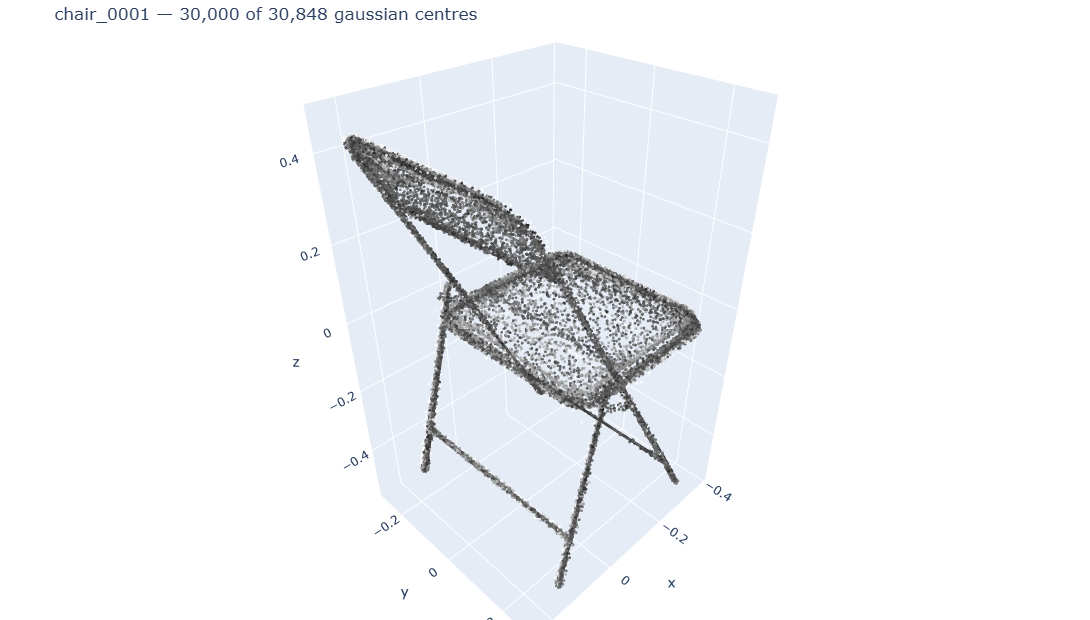

In [14]:
try:
    import plotly.graph_objects as go
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False
    print("plotly not installed -- run  %pip install plotly  and re-run this cell")

if HAVE_PLOTLY:
    n_show = min(30_000, len(sp))
    idx = np.random.default_rng(0).choice(len(sp), n_show, replace=False)
    p, c, o = sp.xyz[idx], sp.rgb[idx], sp.opacity[idx]
    colors = [f"rgb({int(r*255)},{int(g*255)},{int(b*255)})" for r, g, b in c]

    fig = go.Figure(go.Scatter3d(
        x=p[:, 0], y=p[:, 1], z=p[:, 2], mode="markers",
        marker=dict(size=1.6, color=colors, opacity=0.75),
        hovertemplate="(%{x:.3f}, %{y:.3f}, %{z:.3f})<extra></extra>"))
    fig.update_layout(
        title=f"{sp.name} — {n_show:,} of {len(sp):,} gaussian centres",
        width=760, height=620, margin=dict(l=0, r=0, t=40, b=0),
        scene=dict(aspectmode="data",
                   xaxis_title="x", yaxis_title="y", zaxis_title="z"))
    fig.show()

## 6. Real splat rendering

Now the actual thing. The pipeline, in `splatlib.project_gaussians` +
`splatlib.rasterize`:

**a. World → camera.** `x_cam = R x_world + t`.

**b. Project the centre.** `u = fx·X/Z + cx`, `v = fy·Y/Z + cy`.

**c. Project the covariance.** A perspective projection is nonlinear, so an
ellipsoid does not map to an ellipse exactly. EWA splatting linearises it at the
Gaussian's centre using the Jacobian

$$J = \begin{bmatrix} f_x/Z & 0 & -f_x X/Z^2 \\ 0 & f_y/Z & -f_y Y/Z^2\end{bmatrix},
\qquad \Sigma_{2D} = J W \Sigma W^\top J^\top$$

with $\Sigma = RSS^\top R^\top$ built from the scale and quaternion. A small
constant is added to the diagonal — a low-pass filter that stops sub-pixel
Gaussians from disappearing.

**d. Composite.** Each Gaussian contributes
$\alpha_i \exp(-\tfrac12 d^\top \Sigma_{2D}^{-1} d)$ at pixel offset $d$,
blended front-to-back.

The one approximation we make: exact front-to-back compositing is sequential and
unusably slow in Python, so we slice depth into 64 thin slabs, blend
order-independently *within* a slab (transmittance multiplies, so summing
$\log(1-\alpha)$ is exact), and composite the slabs in order. Visually
indistinguishable here.

rendered in 1.81s


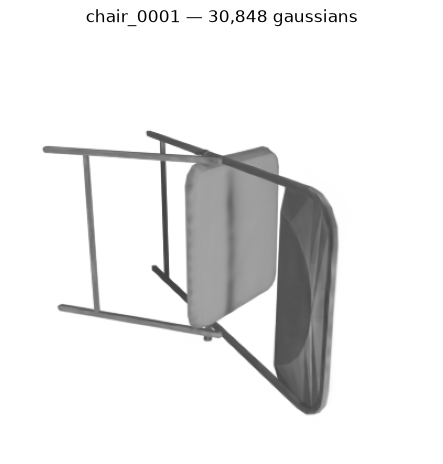

In [22]:
t0 = time.time()
img = sl.render(sp, azim=35, elev=18, H=384, W=384, up_axis=1)
print(f"rendered in {time.time()-t0:.2f}s")

plt.figure(figsize=(5.5, 5.5))
plt.imshow(img)
plt.title(f"{OBJ_ID} — {len(sp):,} gaussians")
plt.axis("off")
plt.show()

In [16]:
img.shape

(384, 384, 3)

If that came out sideways, the up-axis guess is wrong — see the next section.
If it came out empty or a smear, the most likely causes are an unexpected
quaternion convention or scales stored without the `exp`.

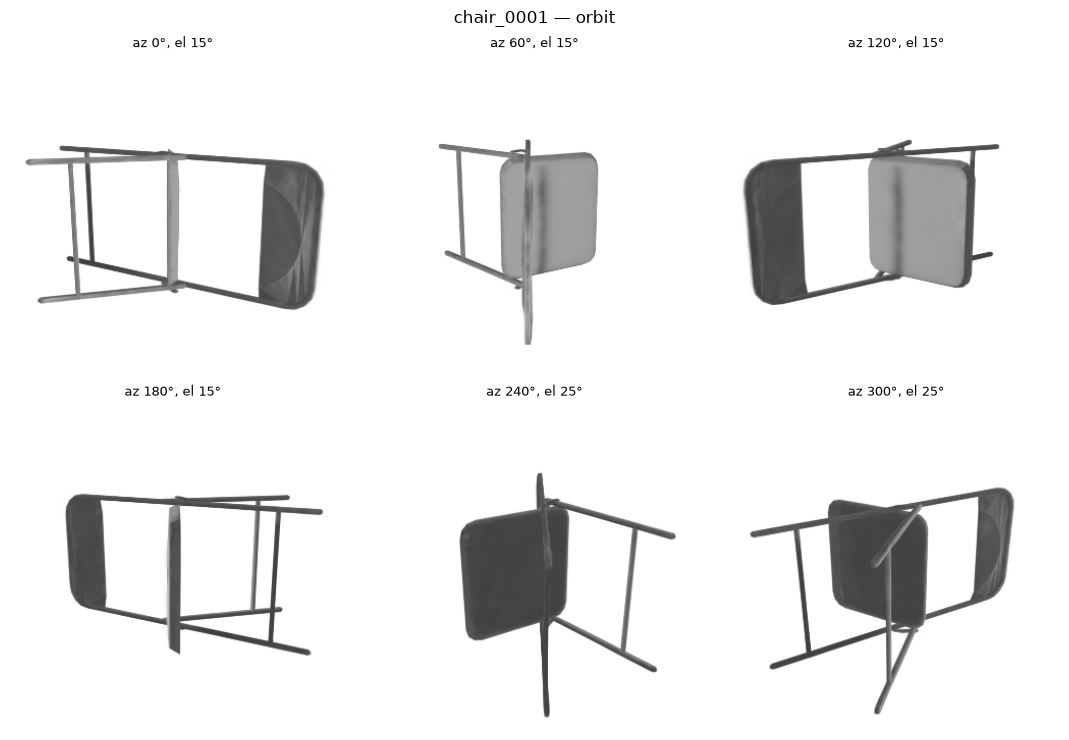

In [21]:
# Orbit
views = [(0, 15), (60, 15), (120, 15), (180, 15), (240, 25), (300, 25)]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for ax, (az, el) in zip(axes.ravel(), views):
    ax.imshow(sl.render(sp, azim=az, elev=el, H=320, W=320, up_axis=1, zoom=0.95))
    ax.set_title(f"az {az}°, el {el}°", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{OBJ_ID} — orbit", y=0.98)
plt.tight_layout()
plt.savefig(OUT / f"{OBJ_ID}_orbit.png", dpi=110, bbox_inches="tight")
plt.show()

## 7. Which axis is up?

ModelNet CAD models are natively **z-up**; most renderers and splatting
pipelines assume **y-up**. Whoever produced ShapeSplats made a choice, and it
matters — a diffusion model trained on inconsistently oriented data will waste
capacity learning the orientation distribution instead of the shape.

Rather than guess, render with each axis as up and look. The correct one shows
the chair standing.

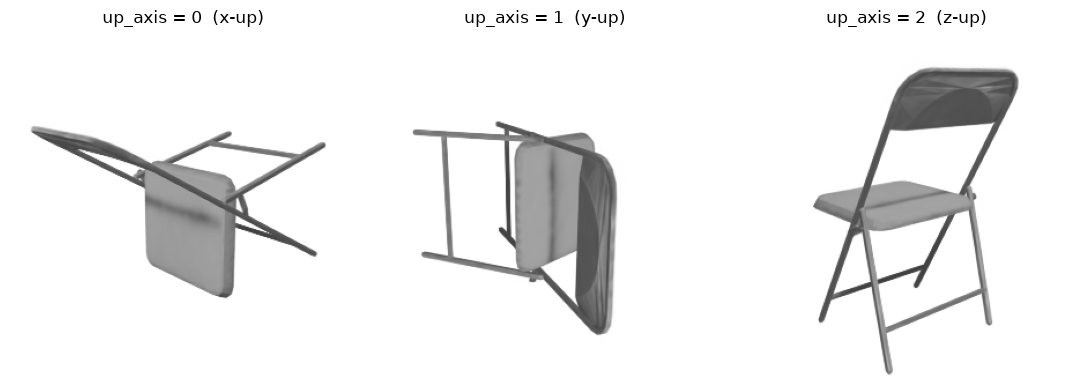

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, axis in zip(axes, [0, 1, 2]):
    ax.imshow(sl.render(sp, azim=40, elev=15, H=300, W=300, up_axis=axis, zoom=0.95))
    ax.set_title(f"up_axis = {axis}  ({'xyz'[axis]}-up)")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [24]:
# Corroborate numerically: for an upright object the vertical axis is usually
# the one with the largest extent, and the mass sits above the geometric centre.
ext = sp.xyz.max(0) - sp.xyz.min(0)
ctr = 0.5 * (sp.xyz.max(0) + sp.xyz.min(0))
skew = (sp.xyz.mean(0) - ctr) / (0.5 * ext)

print(f"{'axis':<6}{'extent':>10}{'skew':>10}")
for i, a in enumerate("xyz"):
    print(f"{a:<6}{ext[i]:>10.4f}{skew[i]:>10.4f}")
print(f"\nlargest extent along: {'xyz'[int(np.argmax(ext))]}")

UP_AXIS = 1   # <-- set from what you saw above
print(f"UP_AXIS set to {UP_AXIS} ({'xyz'[UP_AXIS]})")

axis      extent      skew
x         0.6346    0.1816
y         0.5580    0.0108
z         1.0029    0.0549

largest extent along: z
UP_AXIS set to 1 (y)


## 8. A grid of chairs

One object tells you the format is right. Twelve tell you what the *dataset*
looks like: how much shape variation there is, whether scale and orientation are
consistent, and whether there are broken reconstructions you will need to filter
out before training.

12 objects in 23.0s


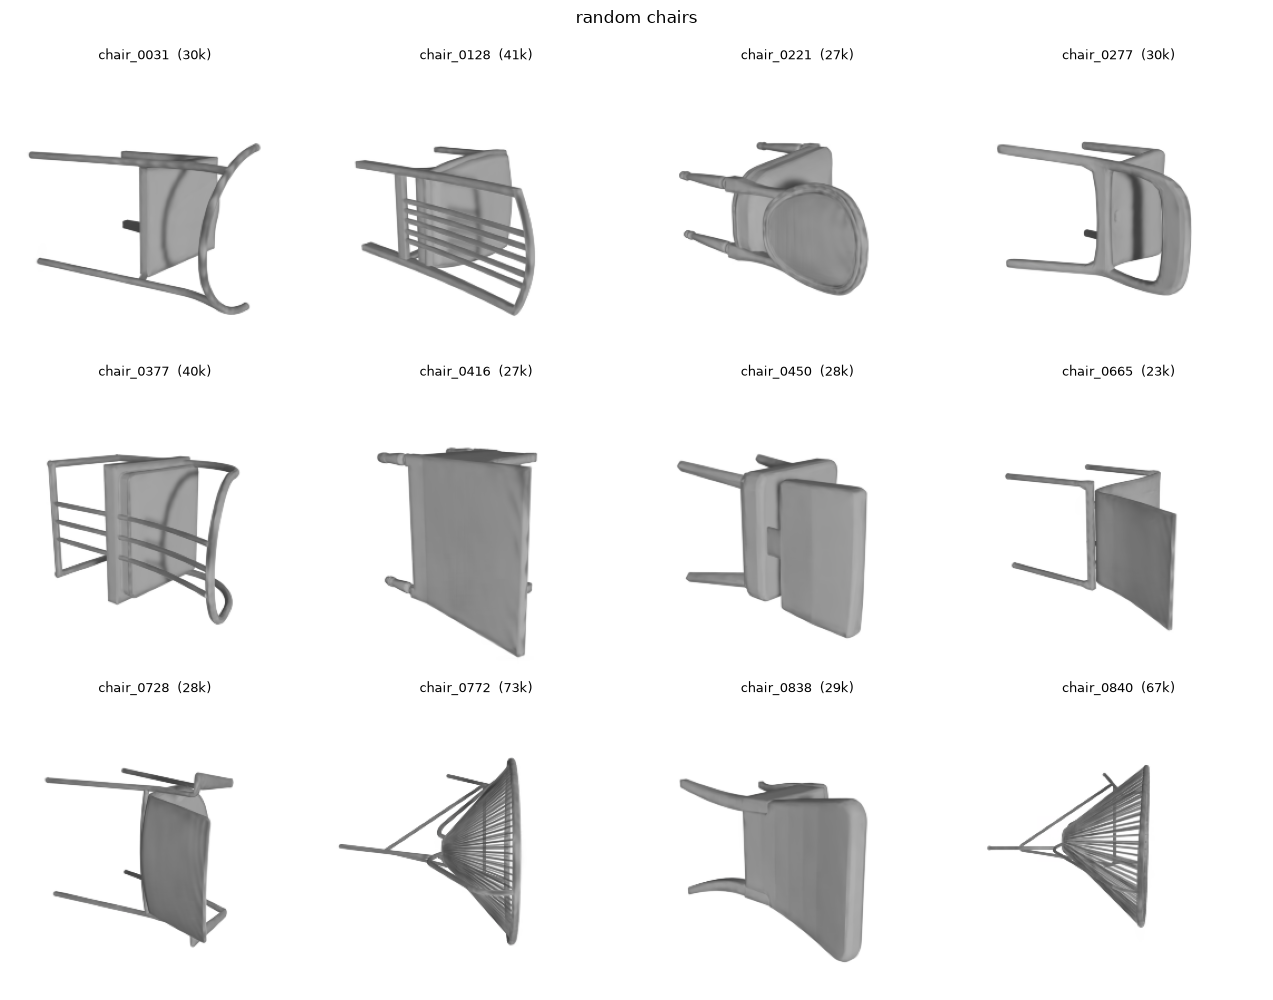

In [25]:
rng = np.random.default_rng(1)
picks = sorted(rng.choice(len(files), min(12, len(files)), replace=False))

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
t0 = time.time()
for ax, i in zip(axes.ravel(), picks):
    s = load(files[i])
    ax.imshow(sl.render(s, azim=40, elev=15, H=260, W=260, up_axis=UP_AXIS, zoom=0.95))
    ax.set_title(f"{object_id(files[i])}  ({len(s)/1000:.0f}k)", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(picks):]:
    ax.axis("off")
print(f"{len(picks)} objects in {time.time()-t0:.1f}s")
fig.suptitle(f"random {CATEGORY}s", y=0.995)
plt.tight_layout()
plt.savefig(OUT / f"{CATEGORY}_grid.png", dpi=110, bbox_inches="tight")
plt.show()

Things worth noting while you look at that grid:

- **Consistent scale?** If some chairs fill the frame and others are tiny, the
  dataset is not pre-normalised and you must normalise before training.
- **Consistent orientation?** Any chair facing a different way is a data
  problem, not a model problem.
- **Floaters.** Semi-transparent blobs away from the object are a normal
  artefact of 3DGS optimisation. Count them in notebook 02 — they are usually
  low-opacity and cheap to prune.
- **Colour.** ModelNet CAD models are untextured, so these come from shaded
  renders. If everything is grey, the 45 SH `f_rest` coefficients may carry
  almost no information — which would cut your per-Gaussian dimensionality from
  59 to 14. Notebook 02 checks this.

Continue in **`02_eda.ipynb`**.